In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyranges as pr
import logging
import scipy.stats as stats
import scipy.signal
import torch
import pyBigWig

logging.basicConfig(level=logging.INFO)

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import lanceotron_mcc.utils as utils
import lanceotron_mcc.signal as signal
import lanceotron_mcc.candidates as candidates

In [25]:
params = candidates.CandidatePeakCallParams(
    max_peak_size=5000,
    window_sizes=[200, 400, 800, 1600, 3200],
)
params.dict()

{'threshold_initial': 9.0,
 'threshold_lst': [2.0, 4.0, 6.0],
 'threshold_background_lst': [10000, 100000, 1000000],
 'window_sizes': [200, 400, 800, 1600, 3200],
 'min_peak_size': 50,
 'max_peak_size': 5000,
 'min_read_count': 5,
 'coverage_depth_per_single_read': 'estimate',
 'background_global_min': 'mean'}

In [26]:
enriched_region_params = candidates.EnrichedRegionsParams(
    background_list=params.threshold_background_lst,
    window_list=params.window_sizes,
    threshold_list=params.threshold_lst,
    min_region_size=params.min_peak_size,
    max_region_size=params.max_peak_size,
    threshold_cumulative=params.threshold_initial,
)

In [27]:
# WIG = "/ceph/project/milne_group/shared/exusers/ncrump/MCC/MYB-FKBP/DMSO_analysis/DMSO_100_combined/FLT3_ext_de_norm_rep_DMSO_100_merged.wig"
# !/ceph/project/milne_group/asmith/software/mambaforge/envs/cc/bin/wigToBigWig $WIG /project/milne_group/shared/seqnado_reference/hg38/UCSC/sequence/hg38.chrom.sizes TMP.bw

In [28]:
# BIGWIG = "/home/a/asmith/project_milne_group/Projects/lanceotron-mcc/mcc_cis/test_data/bigwig/IL6_ext_de_norm_rep_idt_pid_panel_merged.bw"
BIGWIG = "TMP.bw"

In [47]:
peak_caller = candidates.CandidatePeakCallerMCC(BIGWIG, params=params)
peak_caller.set_cis_chromosome()

In [48]:
peak_caller.cis_chromosome

'chr13'

In [49]:
peak_calls = peak_caller.call_candidate_peaks(n_backrgound_chromosomes=3)

2024-09-27 18:07:03.671 | INFO     | lanceotron_mcc.candidates:call_candidate_peaks:445 - Calling candidate peaks for chromosomes: {'chr13', 'chr17'}
Calling candidate peaks for chromosomes: 100%|██████████| 2/2 [02:02<00:00, 61.16s/it]


In [50]:
gr_peak_calls = pr.PyRanges(peak_calls)

In [51]:
gr_peak_calls

,Start,End,Chromosome,Length
0,16058462,16059232,chr13,770.0
1,16100515,16101269,chr13,754.0
2,16104434,16105188,chr13,754.0
3,16113661,16114050,chr13,389.0
4,16117089,16117476,chr13,387.0
...,...,...,...,...
4791,82857216,82858840,chr17,1624.0
4792,82883536,82885184,chr17,1648.0
4793,82886880,82888512,chr17,1632.0
4794,83008768,83010488,chr17,1720.0


In [52]:
gr_peak_calls = gr_peak_calls.df.query("Length > 25").pipe(pr.PyRanges)

In [54]:
gr_peak_calls = gr_peak_calls.merge(slack=1000)

### Extract signal over peak calls

In [55]:
gr_peak_calls = signal.add_signal(gr_peak_calls, BIGWIG)

In [56]:
gr_peak_calls

,Chromosome,Start,End,Signal
0,chr13,16058462,16059232,0.082619
1,chr13,16100515,16101269,0.082619
2,chr13,16104434,16105188,0.082619
3,chr13,16113661,16114050,0.086481
4,chr13,16117089,16117476,0.086481
...,...,...,...,...
4215,chr17,82857216,82858840,0.110135
4216,chr17,82883536,82885184,0.066720
4217,chr17,82886880,82888512,0.086481
4218,chr17,83008768,83010488,0.081900


In [57]:
gr_peak_calls.to_bed("unfiltered.bed")

In [58]:
peak_signal = gr_peak_calls.df["Signal"].values

In [59]:
import skimage.filters

In [64]:
df_peak_calls = gr_peak_calls.df
df_peak_calls["background"] = np.where(
    df_peak_calls.Chromosome == peak_caller.cis_chromosome, 0, 1
)
df_peak_calls

,Chromosome,Start,End,Signal,background
0,chr13,16058462,16059232,0.082619,0
1,chr13,16100515,16101269,0.082619,0
2,chr13,16104434,16105188,0.082619,0
3,chr13,16113661,16114050,0.086481,0
4,chr13,16117089,16117476,0.086481,0
...,...,...,...,...,...
4215,chr17,82857216,82858840,0.110135,1
4216,chr17,82883536,82885184,0.066720,1
4217,chr17,82886880,82888512,0.086481,1
4218,chr17,83008768,83010488,0.081900,1


In [87]:
thresh = df_peak_calls.query("background == 1").Signal.quantile(0.95)

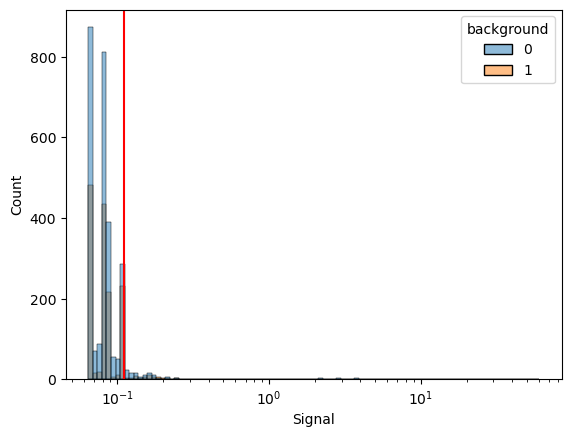

In [88]:
sns.histplot(
    data=df_peak_calls,
    x="Signal",
    bins=100,
    hue=df_peak_calls.background,
    log_scale=[True, False],
)
plt.axvline(thresh, color="red")

In [89]:
gr_peak_calls_filtered = gr_peak_calls.df.query("Signal > @thresh").pipe(pr.PyRanges)
gr_peak_calls_filtered

,Chromosome,Start,End,Signal
0,chr13,17830038,17831650,0.112437
1,chr13,19430308,19431848,0.152111
2,chr13,19444840,19446524,0.128643
3,chr13,19639176,19639972,0.110135
4,chr13,19837388,19838924,0.119811
...,...,...,...,...
217,chr17,78803472,78805096,0.110135
218,chr17,79228280,79229912,0.132205
219,chr17,81173544,81175168,0.128829
220,chr17,81674056,81675688,0.183340


In [90]:
gr_peak_calls_filtered.to_bed("filtered.bed")

# Look at signal processing

In [17]:
chrom_array_window = signal.average_array(chrom_array, window=params.window_sizes[0])
background = signal.average_array(
    chrom_array, window=params.threshold_background_lst[0]
)

In [18]:
enriched = signal.find_enriched_regions(
    chrom_array_window,
    background,
    min_region_size=params.min_peak_size,
    max_region_size=params.max_peak_size,
)

In [19]:
enriched

[[318129, 318501],
 [328698, 329044],
 [415089, 415414],
 [474457, 474717],
 [577752, 578027],
 [741785, 742085],
 [1094517, 1094756],
 [1123579, 1123863],
 [1541552, 1541784],
 [1697190, 1697441],
 [2674247, 2674494],
 [2846372, 2846609],
 [2888442, 2888690],
 [3089712, 3089966],
 [3344637, 3344892],
 [3421924, 3422194],
 [3457948, 3458180],
 [4085379, 4085638],
 [4840617, 4840847],
 [4852578, 4852851],
 [4991544, 4991785],
 [5590684, 5590939],
 [5820017, 5820255],
 [5866768, 5867106],
 [6039455, 6039722],
 [6088023, 6088312],
 [6148901, 6149142],
 [6530048, 6530279],
 [6796428, 6796726],
 [6810923, 6811291],
 [6832557, 6832929],
 [7469130, 7469381],
 [8226275, 8226516],
 [9887649, 9887923],
 [10157150, 10157378],
 [10332266, 10332500],
 [10360920, 10361158],
 [10488127, 10488352],
 [10535054, 10535291],
 [10633086, 10633352],
 [10686276, 10686534],
 [10689596, 10689846],
 [10776899, 10777133],
 [11054891, 11055139],
 [11118051, 11118292],
 [11136308, 11136662],
 [11272138, 11272374],

In [8]:
chrom_array

<1x170805979 sparse array of type '<class 'numpy.float32'>'
	with 49715 stored elements in Compressed Sparse Row format>

In [9]:
signal.moving_average_with_sparse(chrom_array)

/ceph/project/milne_group/asmith/software/mambaforge/envs/ml/lib/python3.10/site-packages/scipy/sparse/_index.py:103: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_intXint(row, col, x.flat[0])


KeyboardInterrupt: 

In [8]:
# import ray

# ray.init(ignore_reinit_error=True, num_cpus=8)

In [9]:
utils.search_enriched_regions_param_grid(
    chrom_array,
    enriched_region_params,
)


KeyboardInterrupt: 